# Sequence modelling (RNN / LSTM)

Model the sequence of events within a session and predict the **next event type**.

Loads **`processed/artifacts.pkl`** saved in `data_preprocessing.ipynb` 

Run `data_preprocessing.ipynb` 


In [7]:
import random
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import display

sns.set_theme(style="whitegrid")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 1. Load stored preprocessing artifacts

In [ ]:
import pickle # for loading preprocessed artifacts

PROCESSED_DIR = Path("processed")
artifacts_path = PROCESSED_DIR / "artifacts.pkl"

if not artifacts_path.exists():
    raise FileNotFoundError(
        "No processed/artifacts.pkl found. Please run data_preprocessing.ipynb through section 10."
    )

with open(artifacts_path, "rb") as f:
    art = pickle.load(f)

RANDOM_STATE = art["random_state"]
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

df_cleaned = art["df_cleaned"]
sessions_df = art["sessions_df"]
train_df = art["train_sessions"]
val_df = art["val_sessions"]
test_df = art["test_sessions"]
event2id = art["event2id"]
id2event = art["id2event"]
NUM_EVENTS = len(event2id)
PAD_IDX = event2id["<pad>"]
PAD_TOKEN = "<pad>"

print("Loaded:", artifacts_path)
print("Cleaned sessions:", len(df_cleaned))
print(f"Sequences — train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")
print("Event vocabulary:", event2id)

Loaded: processed/artifacts.pkl
Cleaned sessions: 6138
Sequences — train: 4296 | val: 921 | test: 921
Event vocabulary: {'<pad>': 0, 'cart': 1, 'click_ad': 2, 'discount': 3, 'purchase': 4, 'view': 5}


In [ ]:
# Already built and split in data_preprocessing.ipynb
print("Sequence length stats:")
print(sessions_df["length"].describe())
display(train_df.head(3))

Sequence length stats:
count    6138.000000
mean       12.959107
std         3.974555
min         2.000000
25%        10.000000
50%        14.000000
75%        16.000000
max        18.000000
Name: length, dtype: float64


,session_id,events,length
0,1,"[view, view, view, view, view, view, view, vie...",15
6,9,"[view, view, view, cart, cart, cart, purchase]",7
7,10,"[view, view, view, view, view, view, view, vie...",17


In [23]:
MAX_LEN = int(sessions_df["length"].quantile(0.95))
print("Number of event types:", NUM_EVENTS)
print("95th percentile sequence length:", MAX_LEN)

Number of event types: 6
95th percentile sequence length: 18


## 2. PyTorch dataset (next-event prediction)

In [11]:
def encode_events(event_list):
    return [event2id[e] for e in event_list]


class NextEventDataset(Dataset):
    def __init__(self, frame):
        self.samples = []
        for events in frame["events"].tolist():
            ids = encode_events(events)
            self.samples.append((ids[:-1], ids[1:]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return (
            torch.tensor(x, dtype=torch.long),
            torch.tensor(y, dtype=torch.long),
        )


def collate_batch(batch):
    xs, ys = zip(*batch)
    x_pad = pad_sequence(xs, batch_first=True, padding_value=PAD_IDX)
    y_pad = pad_sequence(ys, batch_first=True, padding_value=PAD_IDX)
    lengths = torch.tensor([len(x) for x in xs], dtype=torch.long)
    return x_pad, y_pad, lengths

## 3. Models: RNN and LSTM

# Dataset helpers defined in section 2

In [13]:
class NextEventModel(nn.Module):
    def __init__(
        self,
        num_events,
        embed_dim,
        hidden_size,
        num_layers,
        dropout,
        rnn_type="RNN",
    ):
        super().__init__()
        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(num_events, embed_dim, padding_idx=PAD_IDX)
        rnn_dropout = dropout if num_layers > 1 else 0.0
        if rnn_type == "LSTM":
            self.rnn = nn.LSTM(
                embed_dim,
                hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=rnn_dropout,
            )
        else:
            self.rnn = nn.RNN(
                embed_dim,
                hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=rnn_dropout,
            )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_events)

    def forward(self, x):
        emb = self.embedding(x)
        out, _ = self.rnn(emb)
        out = self.dropout(out)
        return self.fc(out)


def run_epoch(model, loader, criterion, optimizer=None):
    train_mode = optimizer is not None
    model.train(train_mode)
    total_loss = 0.0
    all_preds, all_targets = [], []

    for x, y, lengths in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)

        # mask padding positions
        mask = y != PAD_IDX
        loss = criterion(logits[mask], y[mask])

        if train_mode:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * mask.sum().item()
        preds = logits.argmax(dim=-1)
        all_preds.extend(preds[mask].cpu().numpy())
        all_targets.extend(y[mask].cpu().numpy())

    n = len(all_targets)
    avg_loss = total_loss / max(n, 1)
    acc = accuracy_score(all_targets, all_preds) if n else 0.0
    return avg_loss, acc


def train_model(
    rnn_type,
    hidden_size,
    num_layers,
    dropout,
    embed_dim,
    lr,
    batch_size,
    max_epochs=40,
    patience=6,
):
    train_loader = DataLoader(
        NextEventDataset(train_df),
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate_batch,
    )
    val_loader = DataLoader(
        NextEventDataset(val_df),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_batch,
    )

    model = NextEventModel(
        NUM_EVENTS,
        embed_dim,
        hidden_size,
        num_layers,
        dropout,
        rnn_type=rnn_type,
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = None
    wait = 0

    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, best_val_loss

## 5. Hyperparameter search — RNN

In [14]:
# Grid: 3 x 2 x 2 = 12 configs per model (expand lists for a wider search)
param_grid = {
    "hidden_size": [64, 128, 256],
    "num_layers": [1, 2],
    "dropout": [0.0, 0.2],
    "embed_dim": [64],
    "lr": [1e-3],
    "batch_size": [32],
}

rnn_configs = [
    dict(zip(param_grid.keys(), vals))
    for vals in product(*param_grid.values())
]
print("Configurations per model (RNN and LSTM):", len(rnn_configs))

Configurations per model (RNN and LSTM): 12


In [15]:
rnn_results = []

for i, cfg in enumerate(rnn_configs):
    print(f"\n[RNN {i+1}/{len(rnn_configs)}] {cfg}")
    torch.manual_seed(RANDOM_STATE)
    model, hist, best_val_loss = train_model(rnn_type="RNN", **cfg)

    val_loader = DataLoader(
        NextEventDataset(val_df), batch_size=cfg["batch_size"], shuffle=False, collate_fn=collate_batch
    )
    _, val_acc = run_epoch(model, val_loader, nn.CrossEntropyLoss())

    rnn_results.append(
        {
            "model": "RNN",
            "run": i,
            **cfg,
            "best_val_loss": best_val_loss,
            "best_val_acc": max(hist["val_acc"]) if hist["val_acc"] else 0,
            "epochs_ran": len(hist["val_loss"]),
            "history": hist,
            "state_dict": {k: v.cpu().clone() for k, v in model.state_dict().items()},
        }
    )

rnn_results_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "state_dict")} for r in rnn_results])
rnn_results_df = rnn_results_df.sort_values("best_val_loss")
print("\nRNN results (sorted by val loss):")
display(rnn_results_df.head(10))


[RNN 1/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 2/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 3/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 4/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 5/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 6/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 7/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 8/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[RNN 9/12] {'hidden_size': 256, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.0

,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,epochs_ran
4,RNN,4,128,1,0.0,64,0.001,32,0.373583,0.891573,26
2,RNN,2,64,2,0.0,64,0.001,32,0.373991,0.891298,31
6,RNN,6,128,2,0.0,64,0.001,32,0.374277,0.891298,23
11,RNN,11,256,2,0.2,64,0.001,32,0.374529,0.891298,15
8,RNN,8,256,1,0.0,64,0.001,32,0.374698,0.891298,26
7,RNN,7,128,2,0.2,64,0.001,32,0.374846,0.891298,26
10,RNN,10,256,2,0.0,64,0.001,32,0.375364,0.890932,14
3,RNN,3,64,2,0.2,64,0.001,32,0.375501,0.890841,33
9,RNN,9,256,1,0.2,64,0.001,32,0.375876,0.891573,13
5,RNN,5,128,1,0.2,64,0.001,32,0.376852,0.890841,15


according to val loss, best config is hidden_size=256, num_layers=2, dropout=0.2, embed_dim=64, lr=1e-3, batch_size=32

Note: with more epochs, the best config might change as some runs were still improving at epoch 40. will consider increasing max_epochs and patience for a more thorough search.

Best RNN config:


,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,epochs_ran
0,RNN,4,128,1,0.0,64,0.001,32,0.373583,0.891573,26


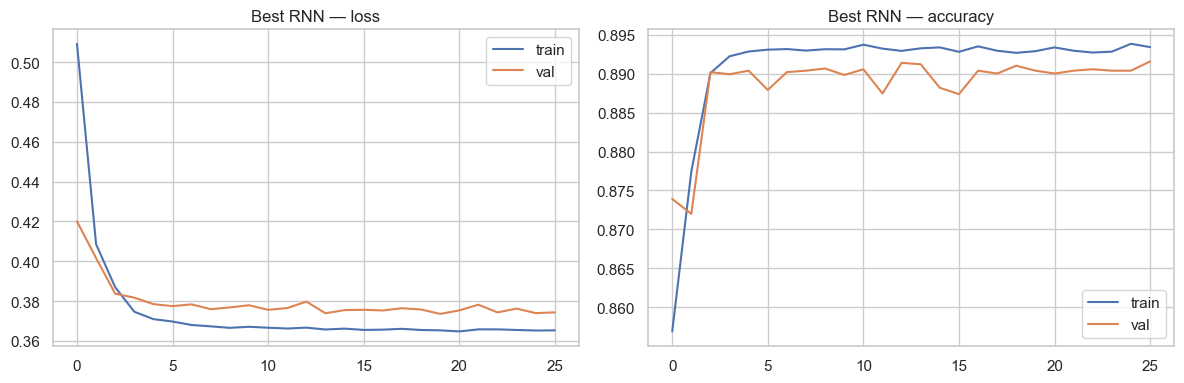

In [16]:
best_rnn = min(rnn_results, key=lambda r: r["best_val_loss"])
print("Best RNN config:")
display(pd.DataFrame([{k: v for k, v in best_rnn.items() if k not in ("history", "state_dict")}]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_rnn["history"]["train_loss"], label="train")
axes[0].plot(best_rnn["history"]["val_loss"], label="val")
axes[0].set_title("Best RNN — loss")
axes[0].legend()
axes[1].plot(best_rnn["history"]["train_acc"], label="train")
axes[1].plot(best_rnn["history"]["val_acc"], label="val")
axes[1].set_title("Best RNN — accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Hyperparameter search — LSTM

In [17]:
lstm_results = []

for i, cfg in enumerate(rnn_configs):
    print(f"\n[LSTM {i+1}/{len(rnn_configs)}] {cfg}")
    torch.manual_seed(RANDOM_STATE)
    model, hist, best_val_loss = train_model(rnn_type="LSTM", **cfg)

    val_loader = DataLoader(
        NextEventDataset(val_df), batch_size=cfg["batch_size"], shuffle=False, collate_fn=collate_batch
    )
    _, val_acc = run_epoch(model, val_loader, nn.CrossEntropyLoss())

    lstm_results.append(
        {
            "model": "LSTM",
            "run": i,
            **cfg,
            "best_val_loss": best_val_loss,
            "best_val_acc": max(hist["val_acc"]) if hist["val_acc"] else 0,
            "epochs_ran": len(hist["val_loss"]),
            "history": hist,
            "state_dict": {k: v.cpu().clone() for k, v in model.state_dict().items()},
        }
    )

lstm_results_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "state_dict")} for r in lstm_results])
lstm_results_df = lstm_results_df.sort_values("best_val_loss")
print("\nLSTM results (sorted by val loss):")
display(lstm_results_df.head(10))


[LSTM 1/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 2/12] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 3/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 4/12] {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 5/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 6/12] {'hidden_size': 128, 'num_layers': 1, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 7/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.0, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 8/12] {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.2, 'embed_dim': 64, 'lr': 0.001, 'batch_size': 32}

[LSTM 9/12] {'hidden_size': 256, 'num_layers': 1, 'dropout': 0.0, 'embed_dim': 64, 

,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,epochs_ran
3,LSTM,3,64,2,0.2,64,0.001,32,0.374103,0.890932,34
8,LSTM,8,256,1,0.0,64,0.001,32,0.374189,0.890383,14
0,LSTM,0,64,1,0.0,64,0.001,32,0.374263,0.890932,28
7,LSTM,7,128,2,0.2,64,0.001,32,0.374295,0.891024,23
2,LSTM,2,64,2,0.0,64,0.001,32,0.374369,0.890932,22
1,LSTM,1,64,1,0.2,64,0.001,32,0.374379,0.891298,39
11,LSTM,11,256,2,0.2,64,0.001,32,0.374422,0.891024,15
10,LSTM,10,256,2,0.0,64,0.001,32,0.374524,0.890383,17
6,LSTM,6,128,2,0.0,64,0.001,32,0.374972,0.890383,20
9,LSTM,9,256,1,0.2,64,0.001,32,0.375398,0.890383,15


Best LSTM config:


,model,run,hidden_size,num_layers,dropout,embed_dim,lr,batch_size,best_val_loss,best_val_acc,epochs_ran
0,LSTM,3,64,2,0.2,64,0.001,32,0.374103,0.890932,34


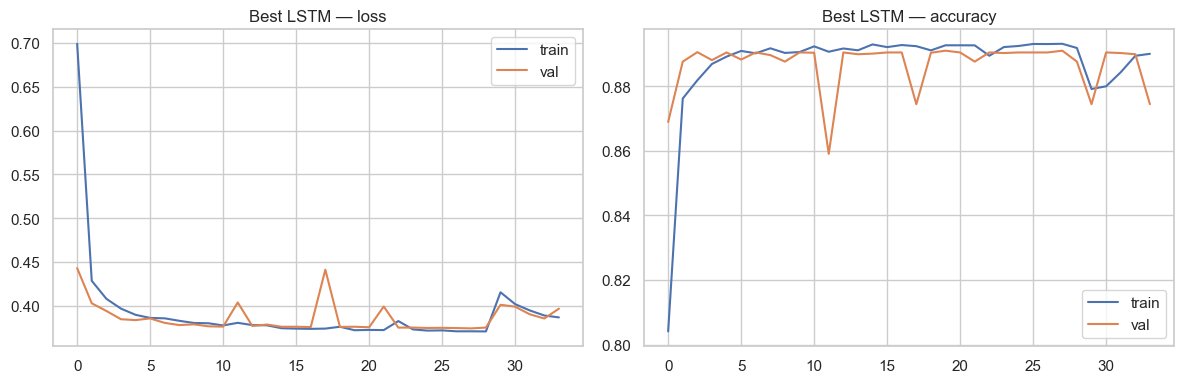

In [18]:
best_lstm = min(lstm_results, key=lambda r: r["best_val_loss"])
print("Best LSTM config:")
display(pd.DataFrame([{k: v for k, v in best_lstm.items() if k not in ("history", "state_dict")}]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_lstm["history"]["train_loss"], label="train")
axes[0].plot(best_lstm["history"]["val_loss"], label="val")
axes[0].set_title("Best LSTM — loss")
axes[0].legend()
axes[1].plot(best_lstm["history"]["train_acc"], label="train")
axes[1].plot(best_lstm["history"]["val_acc"], label="val")
axes[1].set_title("Best LSTM — accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Test-set evaluation (best RNN vs best LSTM)

In [19]:
def evaluate_on_test(result_row):
    cfg = {k: result_row[k] for k in ["hidden_size", "num_layers", "dropout", "embed_dim", "lr", "batch_size"]}
    model = NextEventModel(
        NUM_EVENTS,
        cfg["embed_dim"],
        cfg["hidden_size"],
        cfg["num_layers"],
        cfg["dropout"],
        rnn_type=result_row["model"],
    ).to(DEVICE)
    model.load_state_dict(result_row["state_dict"])

    test_loader = DataLoader(
        NextEventDataset(test_df),
        batch_size=cfg["batch_size"],
        shuffle=False,
        collate_fn=collate_batch,
    )
    loss, acc = run_epoch(model, test_loader, nn.CrossEntropyLoss())
    return loss, acc, model


rnn_test_loss, rnn_test_acc, rnn_model = evaluate_on_test(best_rnn)
lstm_test_loss, lstm_test_acc, lstm_model = evaluate_on_test(best_lstm)

comparison = pd.DataFrame(
    [
        {
            "model": "RNN (best)",
            "hidden_size": best_rnn["hidden_size"],
            "num_layers": best_rnn["num_layers"],
            "dropout": best_rnn["dropout"],
            "embed_dim": best_rnn["embed_dim"],
            "lr": best_rnn["lr"],
            "val_loss": best_rnn["best_val_loss"],
            "val_acc": best_rnn["best_val_acc"],
            "test_loss": rnn_test_loss,
            "test_acc": rnn_test_acc,
        },
        {
            "model": "LSTM (best)",
            "hidden_size": best_lstm["hidden_size"],
            "num_layers": best_lstm["num_layers"],
            "dropout": best_lstm["dropout"],
            "embed_dim": best_lstm["embed_dim"],
            "lr": best_lstm["lr"],
            "val_loss": best_lstm["best_val_loss"],
            "val_acc": best_lstm["best_val_acc"],
            "test_loss": lstm_test_loss,
            "test_acc": lstm_test_acc,
        },
    ]
)
print("Final comparison (validation + test):")
display(comparison)

winner = "LSTM" if lstm_test_acc > rnn_test_acc else "RNN"
print(f"\nWinner on test accuracy: {winner}")

Final comparison (validation + test):


,model,hidden_size,num_layers,dropout,embed_dim,lr,val_loss,val_acc,test_loss,test_acc
0,RNN (best),128,1,0.0,64,0.001,0.373583,0.891573,0.380988,0.887076
1,LSTM (best),64,2,0.2,64,0.001,0.374103,0.890932,0.381058,0.888182



Winner on test accuracy: LSTM


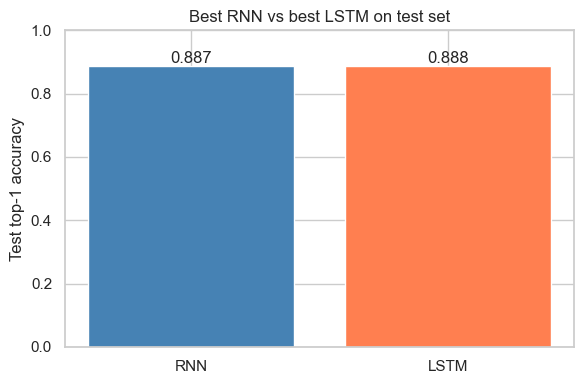

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
x = ["RNN", "LSTM"]
vals = [rnn_test_acc, lstm_test_acc]
ax.bar(x, vals, color=["steelblue", "coral"])
ax.set_ylabel("Test top-1 accuracy")
ax.set_title("Best RNN vs best LSTM on test set")
ax.set_ylim(0, 1)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.show()

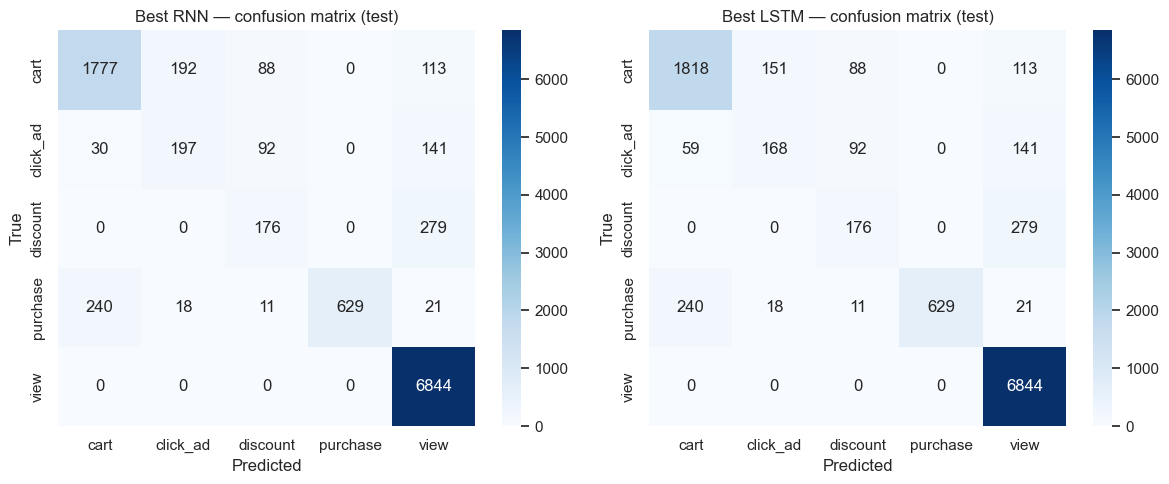

In [21]:
def collect_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for x, y, _ in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            mask = y != PAD_IDX
            preds.extend(logits.argmax(-1)[mask].cpu().numpy())
            targets.extend(y[mask].cpu().numpy())
    return np.array(targets), np.array(preds)


test_loader = DataLoader(
    NextEventDataset(test_df), batch_size=32, shuffle=False, collate_fn=collate_batch
)

y_true, y_pred_rnn = collect_predictions(rnn_model, test_loader)
_, y_pred_lstm = collect_predictions(lstm_model, test_loader)

labels = [id2event[i] for i in range(1, NUM_EVENTS)]
label_ids = list(range(1, NUM_EVENTS))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in zip(
    axes,
    [y_pred_rnn, y_pred_lstm],
    ["Best RNN", "Best LSTM"],
):
    cm = confusion_matrix(y_true, pred, labels=label_ids)
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, ax=ax, cmap="Blues")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{title} — confusion matrix (test)")
plt.tight_layout()
plt.show()

## 8. Example next-event predictions

In [22]:
def predict_next_events(model, event_ids):
    """event_ids = input sequence (all but last event); returns predicted next events."""
    model.eval()
    x = torch.tensor([event_ids], dtype=torch.long).to(DEVICE)
    with torch.no_grad():
        logits = model(x)
        pred_ids = logits.argmax(dim=-1).cpu().numpy()[0]
    return [id2event[i] for i in pred_ids]


print("Sample sessions (true next vs RNN vs LSTM):")
for i in range(min(5, len(test_df))):
    events = test_df.iloc[i]["events"]
    ids = encode_events(events)
    inp, true_next = ids[:-1], [id2event[j] for j in ids[1:]]
    rnn_pred = predict_next_events(rnn_model, inp)
    lstm_pred = predict_next_events(lstm_model, inp)
    print(f"\nSession {i}: {' -> '.join(events)}")
    print("  True next:", true_next)
    print("  RNN pred:", rnn_pred)
    print("  LSTM pred:", lstm_pred)

Sample sessions (true next vs RNN vs LSTM):

Session 0: view -> discount -> click_ad -> cart -> cart -> cart -> purchase
  True next: ['discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  RNN pred: ['view', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  LSTM pred: ['view', 'cart', 'cart', 'cart', 'cart', 'purchase']

Session 1: view -> view -> view -> view -> view -> view -> view -> view -> view -> view -> view -> view -> discount -> click_ad -> cart -> cart -> cart -> purchase
  True next: ['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  RNN pred: ['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']
  LSTM pred: ['view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'view', 'discount', 'click_ad', 'cart', 'cart', 'cart', 'purchase']

Session 2: view -> 

## 9. Summary 

- All data loaded from **`processed/artifacts.pkl`** (saved in preprocessing).
- Event sequences are **synthetic** from aggregate session fields.
- Hyperparameter grid: hidden size, layers, dropout, embedding dim, learning rate.
- Best config per architecture chosen by **lowest validation loss** (early stopping).
- Final decision: compare **test accuracy** and **test loss** between best RNN and best LSTM.
- Mention limitations: no real timestamps, funnel assumptions, class imbalance (`purchase` rare in sequences).